# Load Data

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("gpiosenka/butterfly-images40-species")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'butterfly-images40-species' dataset.
Path to dataset files: /kaggle/input/butterfly-images40-species


In [3]:
import tensorflow as tf

# check whether a GPU is connected
gpu_count = len(tf.config.list_physical_devices('GPU'))
if gpu_count > 0:
    print('GPU is on. Training will be fast.')
else:
    print('WARNING: No GPU. Go to Runtime, Change runtime type, and select T4 GPU before training.')

GPU is on. Training will be fast.


In [4]:
import os
import pandas as pd

print("Files in directory:", os.listdir(path))

Files in directory: ['training.csv.csv', 'butterflies and moths.csv', 'EfficientNetB0-100-(224 X 224)- 97.59.h5', 'valid', 'test', 'train']


### Step 1: Explore the Data

In [5]:
# List the top-level items: train, test, valid folders and the CSV/model files
print(os.listdir(path))

['training.csv.csv', 'butterflies and moths.csv', 'EfficientNetB0-100-(224 X 224)- 97.59.h5', 'valid', 'test', 'train']


In [6]:
# load df

# define the csv_path using the dataset directory path and the file name
csv_path = os.path.join(path, "butterflies and moths.csv")

#  load df
df = pd.read_csv(csv_path)

# check rows and columns
print(f"Total Rows & Columns: {df.shape}")
print("\nMissing values in each column:")
print(df.isnull().sum())

Total Rows & Columns: (13594, 4)

Missing values in each column:
class id     0
filepaths    0
labels       0
data set     0
dtype: int64


In [7]:
# preview the data
display(df.head())

,class id,filepaths,labels,data set
0,0,train/ADONIS/001.jpg,ADONIS,train
1,0,train/ADONIS/002.jpg,ADONIS,train
2,0,train/ADONIS/003.jpg,ADONIS,train
3,0,train/ADONIS/004.jpg,ADONIS,train
4,0,train/ADONIS/005.jpg,ADONIS,train


In [8]:
# Count the images in each split (train, test, valid)
# walk through each split folder and count the .jpg files
for split in ['train', 'test', 'valid']:
    count = 0
    for root, dirs, files in os.walk(os.path.join(path, split)):
        count += len([f for f in files if f.lower().endswith('.jpg')])
    print(split, "images:", count)

train images: 12594
test images: 500
valid images: 500


In [9]:
# count the species (number of folders) in each split

# each species has its own folder inside train, test, and valid
for split in ['train', 'test', 'valid']:
    species_folders = os.listdir(os.path.join(path, split))
    print(split, "species folders:", len(species_folders))

train species folders: 100
test species folders: 100
valid species folders: 100


In [10]:
# load the CSV and check how many images each species has in train
# the CSV lists every image with its species label and split
df = pd.read_csv(os.path.join(path, 'butterflies and moths.csv'))

# count the training images for each species
train_counts = df[df['data set'] == 'train']['labels'].value_counts()
print("Min images per species in train:", train_counts.min())
print("Max images per species in train:", train_counts.max())

Min images per species in train: 100
Max images per species in train: 187


In [11]:
# look at the file names inside one species folder
first_species = os.listdir(os.path.join(path, 'train'))[0]
print("Species:", first_species)
print(os.listdir(os.path.join(path, 'train', first_species))[:10])

Species: PIPEVINE SWALLOW
['029.jpg', '014.jpg', '109.jpg', '034.jpg', '024.jpg', '033.jpg', '094.jpg', '049.jpg', '048.jpg', '115.jpg']


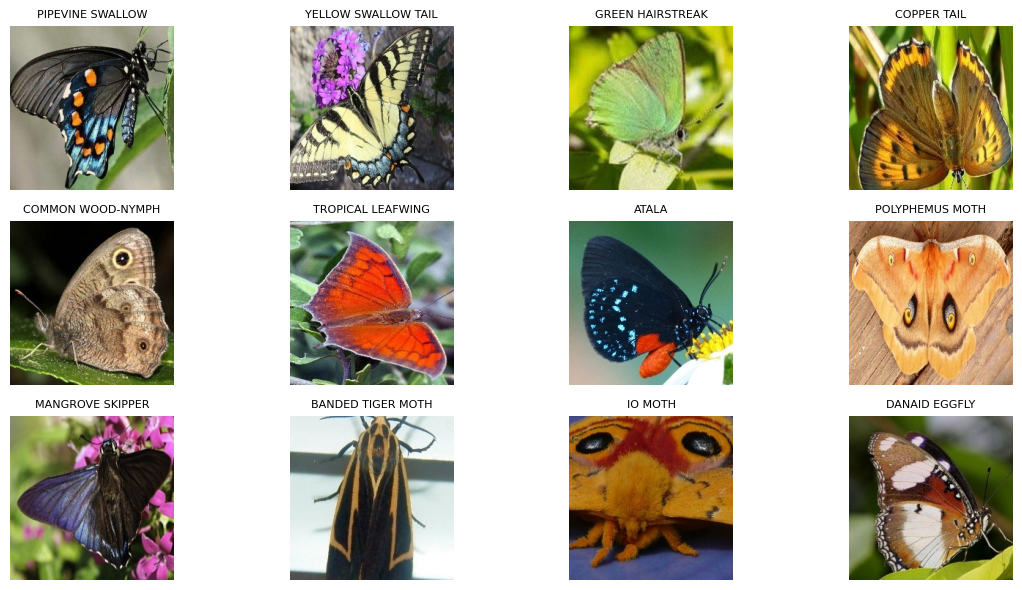

In [12]:
# picking 12 random training rows from the CSV
import matplotlib.pyplot as plt
from PIL import Image #load images

sample = df[df['data set'] == 'train'].sample(12, random_state=1)

plt.figure(figsize=(12, 6))
for i, (_, row) in enumerate(sample.iterrows()):
    plt.subplot(3, 4, i + 1)
    plt.imshow(Image.open(os.path.join(path, row['filepaths'])))
    plt.title(row['labels'], fontsize=8)   # the species name
    plt.axis('off')
plt.tight_layout()
plt.show()

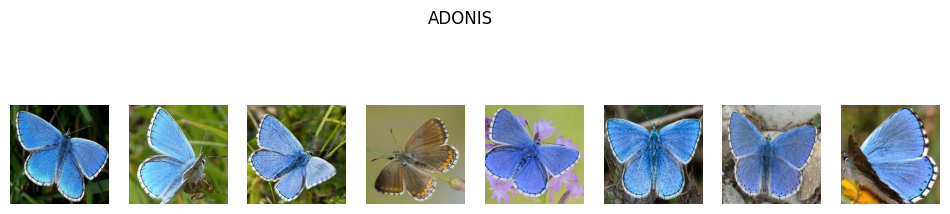

In [13]:
# how several images of one species to see how much they vary
# pick one species and look at 8 of its training images
species = 'ADONIS'
sample = df[(df['data set'] == 'train') & (df['labels'] == species)].head(8)

plt.figure(figsize=(12, 3))
for i, (_, row) in enumerate(sample.iterrows()):
    plt.subplot(1, 8, i + 1)
    plt.imshow(Image.open(os.path.join(path, row['filepaths'])))
    plt.axis('off')
plt.suptitle(species)
plt.show()

## Select a training subset/ Load the photos

- The professor asked us to use 20 training images from each of the 100 species.

- This gives about 2,000 training images in total.

- We pick the images randomly with a fixed random seed, so the selection can be repeated.

What we have
Dataset: 100 butterfly and moth species, with train, test, and valid folders. Each image is 224 × 224 color (RGB).
Training subset: 2,000 images, 20 random images from each of the 100 species.
Validation set: 500 images, 5 per species.
Test set: 500 images, 5 per species. We have not used it yet, and we will keep it for the final score.

In [14]:
# SELECTING 20-per-species selection
# keep only the training rows from the CSV
train_df = df[df['data set'] == 'train']

# for each species, randomly pick 20 rows (random_state makes the pick repeatable)
small_train = train_df.groupby('labels', group_keys=False).sample(n=20, random_state=42)

# check
print("Total selected:", len(small_train))
print(small_train['labels'].value_counts().describe())

Total selected: 2000
count    100.0
mean      20.0
std        0.0
min       20.0
25%       20.0
50%       20.0
75%       20.0
max       20.0
Name: count, dtype: float64


# Modeling
- goal is to build a program that looks at a photo of a butterfly or moth and correctly names its species, out of 100 possible species.

# Baseline CNN Model

In [19]:
# Select 20 training images from each species
train_df = df[df['data set'] == 'train']

selected_df = train_df.groupby('labels').sample(
    n=20,
    random_state=42
)

print("Training images:", len(selected_df))
print("Number of species:", selected_df['labels'].nunique())

Training images: 2000
Number of species: 100


# Preparing Images for the CNN

In [20]:
import tensorflow as tf
import numpy as np

IMG_SIZE = (128, 128)
BATCH_SIZE = 32

# Keep species labels in alphabetical order
class_names = sorted(df['labels'].unique())
class_to_number = {
    name: i for i, name in enumerate(class_names)
}

def make_dataset(data, shuffle=False):
    paths = [
        os.path.join(path, p)
        for p in data['filepaths']
    ]
    labels = [
        class_to_number[name]
        for name in data['labels']
    ]

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    def load_image(file_path, label):
        image = tf.io.read_file(file_path)
        image = tf.io.decode_jpeg(image, channels=3)
        image = tf.image.resize(image, IMG_SIZE)
        image = tf.cast(image, tf.float32) / 255.0
        return image, label

    # mix the photos so each batch contains many different species
    if shuffle:
        dataset = dataset.shuffle(len(paths), seed=42)

    dataset = dataset.map(load_image)
    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# Only the training data is shuffled
train_data = make_dataset(selected_df, shuffle=True)
valid_data = make_dataset(df[df['data set'] == 'valid'])
test_data = make_dataset(df[df['data set'] == 'test'])

print("Datasets are ready")

Datasets are ready


# Build the baseline CNN

In [21]:

from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),   # replaces flatten, for fewer parameters
    layers.Dropout(0.3),               # reduces overfitting
    layers.Dense(128, activation='relu'),
    layers.Dense(100, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        12,900 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,660 (479.14 KB)

 Trainable params: 122,660 (479.14 KB)

 Non-trainable params: 0 (0.00 B)

#### The code block above is a basic CNN with two convolutional layers and two max-pooling layers. The final layer has 100 outputs, one for each species.

# Train the CNN

In [22]:
history = model.fit(
    train_data,
    validation_data=valid_data,
    epochs=10
)

Epoch 1/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 24s 224ms/step - accuracy: 0.0060 - loss: 4.6078 - val_accuracy: 0.0200 - val_loss: 4.5993
Epoch 2/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.0160 - loss: 4.5570 - val_accuracy: 0.0260 - val_loss: 4.3934
Epoch 3/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.0220 - loss: 4.4000 - val_accuracy: 0.0360 - val_loss: 4.2688
Epoch 4/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.0380 - loss: 4.2712 - val_accuracy: 0.0560 - val_loss: 4.0480
Epoch 5/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 50ms/step - accuracy: 0.0545 - loss: 4.1074 - val_accuracy: 0.0740 - val_loss: 3.9379
Epoch 6/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.0555 - loss: 3.9658 - val_accuracy: 0.0640 - val_loss: 3.8342
Epoch 7/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.0640 - loss: 3.8769 - val_accuracy: 0.0800 - val_loss: 3.7026
Epoch 8/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.0815 - loss: 3.8368 - val_accuracy: 0.0900 -

# Visual Evaluation of the Baseline CNN


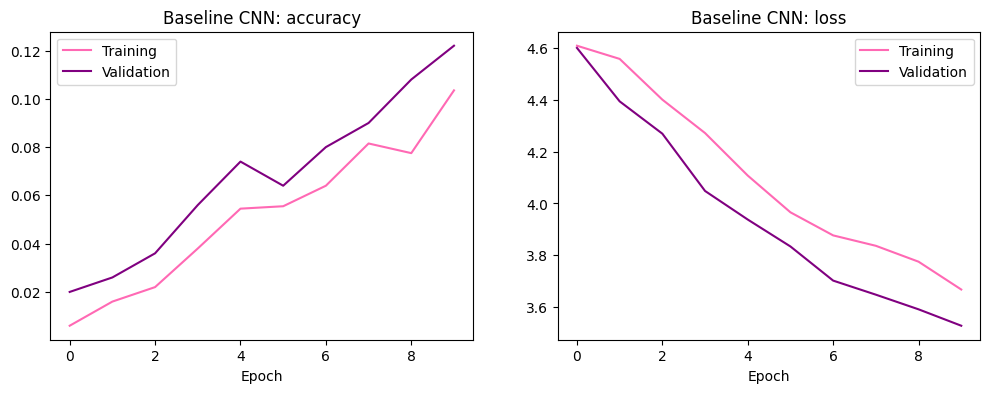

In [23]:
# Training curves
import matplotlib.pyplot as plt

# plot training vs validation accuracy and loss
def plot_history(history, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(history.history['accuracy'], label='Training', color='hotpink')
    ax[0].plot(history.history['val_accuracy'], label='Validation', color='purple')
    ax[0].set_title(title + ': accuracy')
    ax[0].set_xlabel('Epoch')
    ax[0].legend()
    ax[1].plot(history.history['loss'], label='Training', color='hotpink')
    ax[1].plot(history.history['val_loss'], label='Validation', color='purple')
    ax[1].set_title(title + ': loss')
    ax[1].set_xlabel('Epoch')
    ax[1].legend()
    plt.show()

plot_history(history, 'Baseline CNN')

The left graph shows how often the model guesses the right species. The right graph shows how wrong its guesses are, where lower is better. Both lines move in the right direction, so the model is learning. The validation line is the score on photos the model did not train on. It rose from about 2% to about 12%. Random guessing among 100 species would score about 1%, so this is a real improvement, though still low. Both lines were still moving at the end ---- more training would likely help.

In [24]:
# get the true labels and predictions for the validation photos

from sklearn.metrics import confusion_matrix, accuracy_score

# validation dataset is not shuffled, so the true labels line up with the predictions
y_valid_true = np.concatenate([y.numpy() for _, y in valid_data])
probs = model.predict(valid_data, verbose=0)    # probability for each of the 100 species
y_valid_pred = np.argmax(probs, axis=1)         # the most likely species

print('Validation accuracy:', round(accuracy_score(y_valid_true, y_valid_pred), 4))
print('Correct:', (y_valid_true == y_valid_pred).sum(), 'of', len(y_valid_true))

Validation accuracy: 0.122
Correct: 61 of 500


Out of 500 validation photos, the model named the correct species for 61 of them, which is about 12%.

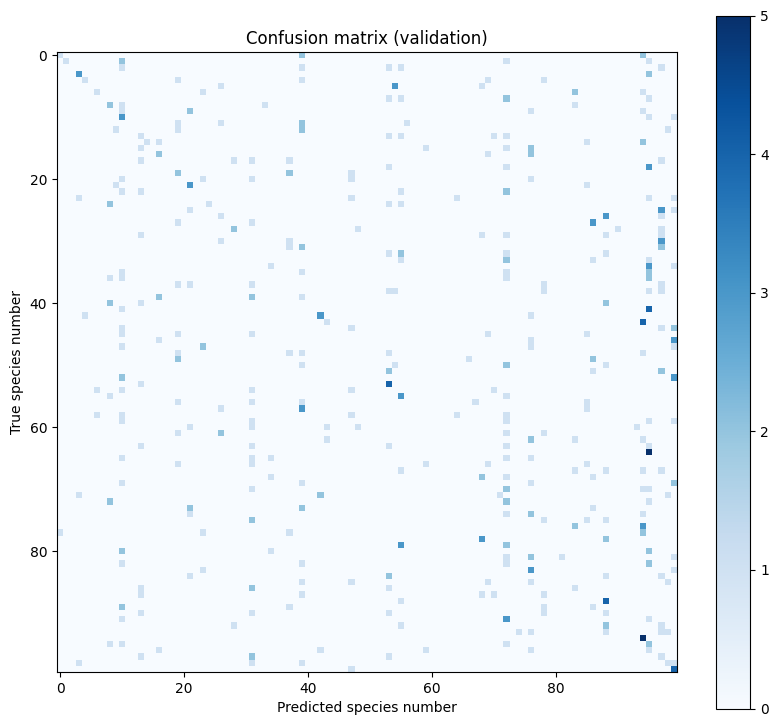

In [25]:
# Confusion matrix
# each row is a true species, each column is the predicted species
# bright squares on the diagonal are correct predictions
cm = confusion_matrix(y_valid_true, y_valid_pred, labels=range(100))

plt.figure(figsize=(10, 9))
plt.imshow(cm, cmap='Blues')
plt.title('Confusion matrix (validation)')
plt.xlabel('Predicted species number')
plt.ylabel('True species number')
plt.colorbar()
plt.show()


Each row is a real species and each column is what the model guessed. A dark square on the diagonal line (top left to bottom right) means the model got that species right. Dark squares off the diagonal are mistakes. Most of the squares are light, which means the mistakes are spread out. A few darker spots show species the model mixes up often.

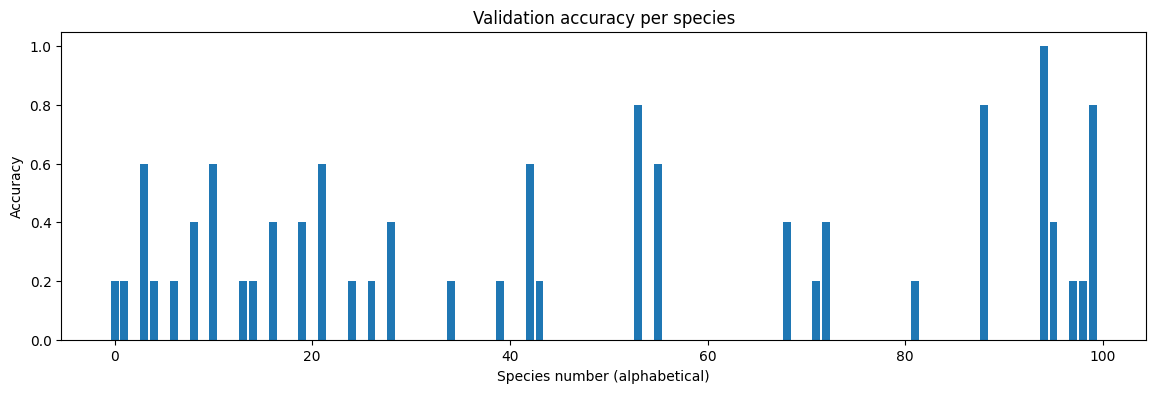

Species with no correct predictions: 69


In [26]:
# Per-species accuracy
# accuracy for each species: correct / total for that species
per_class = cm.diagonal() / cm.sum(axis=1)

plt.figure(figsize=(14, 4))
plt.bar(range(100), per_class)
plt.title('Validation accuracy per species')
plt.xlabel('Species number (alphabetical)')
plt.ylabel('Accuracy')
plt.show()

print('Species with no correct predictions:', (per_class == 0).sum())

In [27]:
# The species most often confused with each other
# find the biggest mistakes (off the diagonal of the confusion matrix)
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)
top = np.argsort(cm_off.ravel())[::-1][:10]

for idx in top:
    true_id, pred_id = np.unravel_index(idx, cm_off.shape)
    if cm_off[true_id, pred_id] > 0:
        print(f"{class_names[true_id]} was predicted as {class_names[pred_id]}: {cm_off[true_id, pred_id]} times")

MONARCH was predicted as VICEROY: 5 times
GLITTERING SAPPHIRE was predicted as ULYSES: 4 times
GARDEN TIGER MOTH was predicted as VICEROY: 4 times
CLEARWING MOTH was predicted as WOOD SATYR: 3 times
STRAITED QUEEN was predicted as PEACOCK: 3 times
INDRA SWALLOW was predicted as ZEBRA LONG WING: 3 times
ARCIGERA FLOWER MOTH was predicted as Iphiclus sister: 3 times
PURPLISH COPPER was predicted as ORANGE TIP: 3 times
POPINJAY was predicted as ULYSES: 3 times
RED SPOTTED PURPLE was predicted as POPINJAY: 3 times


These are the pairs of species the model mixes up most often. For example, “MONARCH was predicted as VICEROY” means the model saw monarch photos and guessed viceroy 5 times. Monarchs and viceroys look very similar, so this is an understandable mistake.

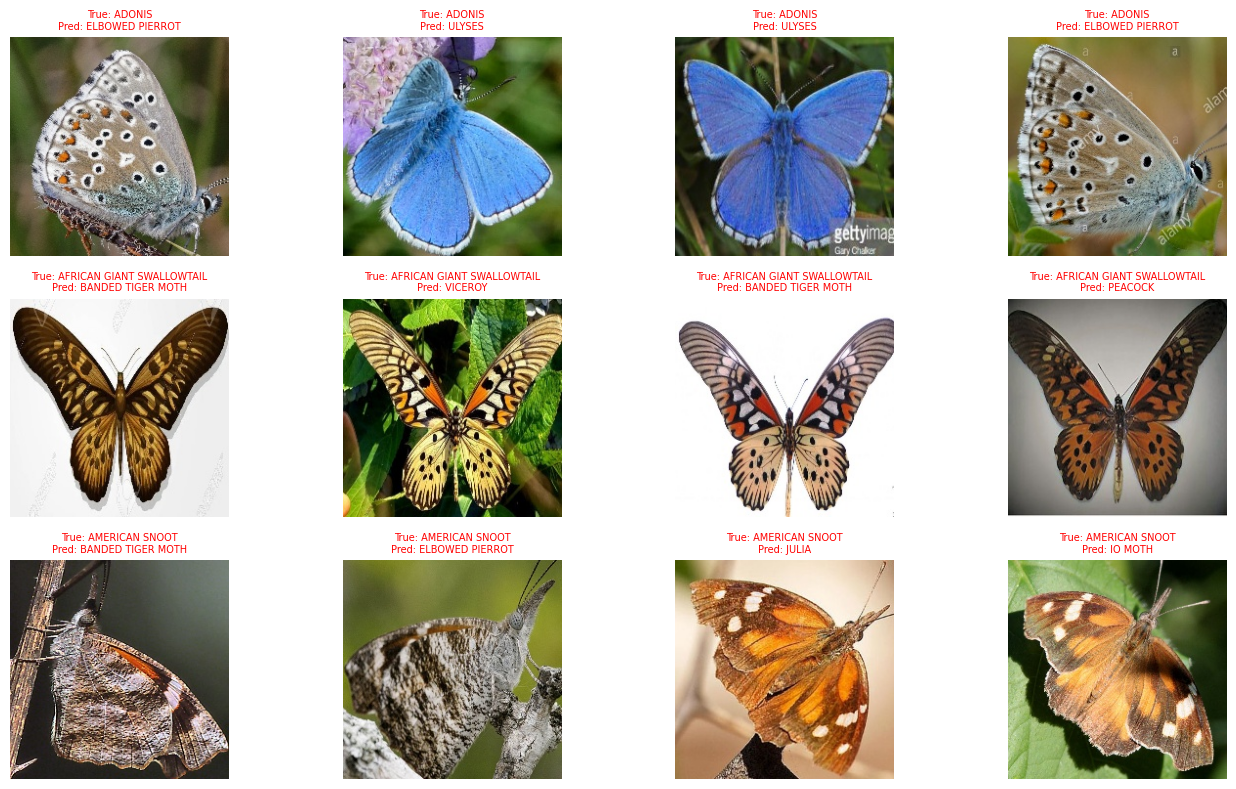

In [28]:
# examples of wrong predictions

# show 12 validation photos the model got wrong
val_rows = val_df.reset_index(drop=True)   # same order as the validation dataset
wrong = np.where(y_valid_true != y_valid_pred)[0][:12]

plt.figure(figsize=(14, 8))
for i, idx in enumerate(wrong):
    img = Image.open(os.path.join(path, val_rows.loc[idx, 'filepaths']))
    plt.subplot(3, 4, i + 1)
    plt.imshow(img)
    plt.title(f"True: {class_names[y_valid_true[idx]]}\nPred: {class_names[y_valid_pred[idx]]}",
              fontsize=7, color='red')
    plt.axis('off')
plt.tight_layout()
plt.show()

These are examples of photos the model got wrong. The title shows the real species (True) and the model’s guess (Pred). Many of the mistakes are between species that look alike, such as blue butterflies. Some photos are also hard, with the butterfly wings folded.

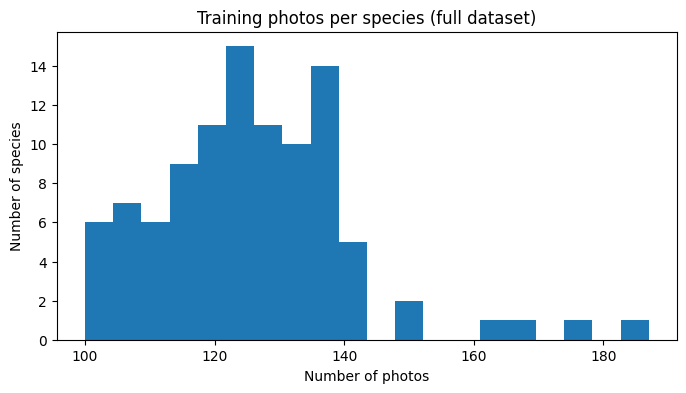

In [29]:
# How many training photos each species has
# histogram of training photos per species in the full dataset
counts_full = train_df['labels'].value_counts()

plt.figure(figsize=(8, 4))
plt.hist(counts_full.values, bins=20, )
plt.title('Training photos per species (full dataset)')
plt.xlabel('Number of photos')
plt.ylabel('Number of species')
plt.show()

This shows how many training photos each species has in the full dataset. Most species have between 100 and 140 photos, and a few have more than 150. We took the same 20 photos from each species, so the sample is balanced even though the full dataset is not.

# Transfer learning models

Next we add the two pretrained models, EfficientNetB0 and MobileNetV2. They already know edges and shapes from ImageNet, meaning that the score shouldbe much higher than the baseline.

## Build a transfer learning model

In [30]:
from tensorflow.keras.applications import EfficientNetB0, MobileNetV2

# build a model: pretrained base (frozen) + our own small head for 100 species
def build_transfer(base_class, scale, name):
    base = base_class(include_top=False, weights='imagenet',
                      input_shape=(128, 128, 3), pooling='avg')
    base.trainable = False                              # keep the pretrained weights fixed

    model = models.Sequential([
        layers.Input(shape=(128, 128, 3)),
        layers.Lambda(scale),          # convert pixels to the range this model expects
        base,                                           # pretrained feature extractor
        layers.Dropout(0.3),
        layers.Dense(128, activation='relu'),
        layers.Dense(100, activation='softmax'),   # one probability per species
    ], name=name)

    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

In [31]:
effnet = build_transfer(EfficientNetB0, lambda x: x * 255.0, 'efficientnetb0')
mobnet = build_transfer(MobileNetV2, lambda x: x * 2.0 - 1.0, 'mobilenetv2')
effnet.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "efficientnetb0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda (Lambda)                 │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 1280)           │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 100)            │        12,900 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,226,439 (16.12 MB)

 Trainable params: 176,868 (690.89 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

## Train EfficientNetB0

Epoch 1/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 112s 1s/step - accuracy: 0.1495 - loss: 4.0639 - val_accuracy: 0.4680 - val_loss: 2.9451
Epoch 2/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step - accuracy: 0.5640 - loss: 2.1888 - val_accuracy: 0.7140 - val_loss: 1.4980
Epoch 3/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - accuracy: 0.7565 - loss: 1.1680 - val_accuracy: 0.7780 - val_loss: 1.0113
Epoch 4/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - accuracy: 0.8375 - loss: 0.7758 - val_accuracy: 0.7980 - val_loss: 0.8412
Epoch 5/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 51ms/step - accuracy: 0.8790 - loss: 0.5836 - val_accuracy: 0.8040 - val_loss: 0.7275
Epoch 6/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - accuracy: 0.8935 - loss: 0.4654 - val_accuracy: 0.8340 - val_loss: 0.6362
Epoch 7/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.9145 - loss: 0.3819 - val_accuracy: 0.8460 - val_loss: 0.5660
Epoch 8/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.9205 - loss: 0.3303 - val_accuracy: 0.8420 - v

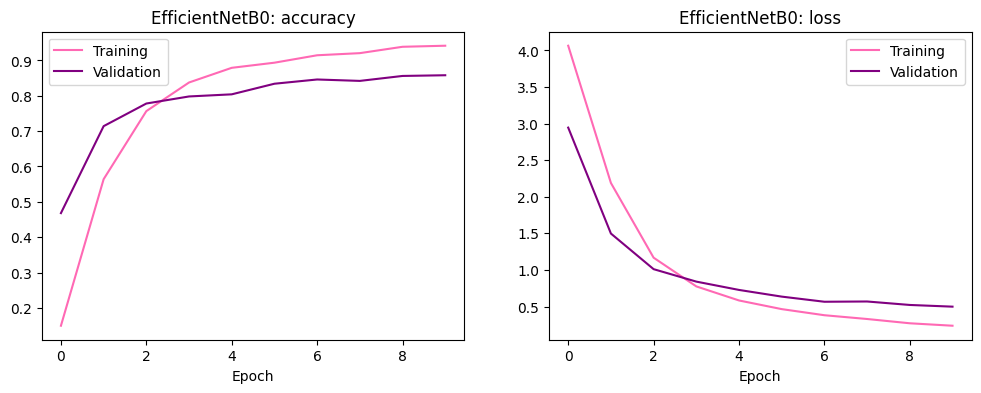

In [32]:
# Train only the new head for 10 epochs
history_eff = effnet.fit(train_data, validation_data=valid_data, epochs=10)
plot_history(history_eff, 'EfficientNetB0')

EfficientNetB0: the validation line stays above 85% and flattens out at the end. Training reaches about 94%, so there is a small gap between the two lines. --- That is normal and not a concern.

## Train MobileNetV2

Epoch 1/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 50s 544ms/step - accuracy: 0.1075 - loss: 4.1559 - val_accuracy: 0.3980 - val_loss: 2.9517
Epoch 2/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.5215 - loss: 2.0677 - val_accuracy: 0.6440 - val_loss: 1.4759
Epoch 3/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.7705 - loss: 0.9809 - val_accuracy: 0.7320 - val_loss: 1.0487
Epoch 4/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.8535 - loss: 0.5975 - val_accuracy: 0.7580 - val_loss: 0.8903
Epoch 5/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - accuracy: 0.9045 - loss: 0.4003 - val_accuracy: 0.7860 - val_loss: 0.7800
Epoch 6/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step - accuracy: 0.9375 - loss: 0.2886 - val_accuracy: 0.8020 - val_loss: 0.7287
Epoch 7/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - accuracy: 0.9495 - loss: 0.2274 - val_accuracy: 0.7920 - val_loss: 0.7089
Epoch 8/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - accuracy: 0.9640 - loss: 0.1787 - val_accuracy: 0.8060 -

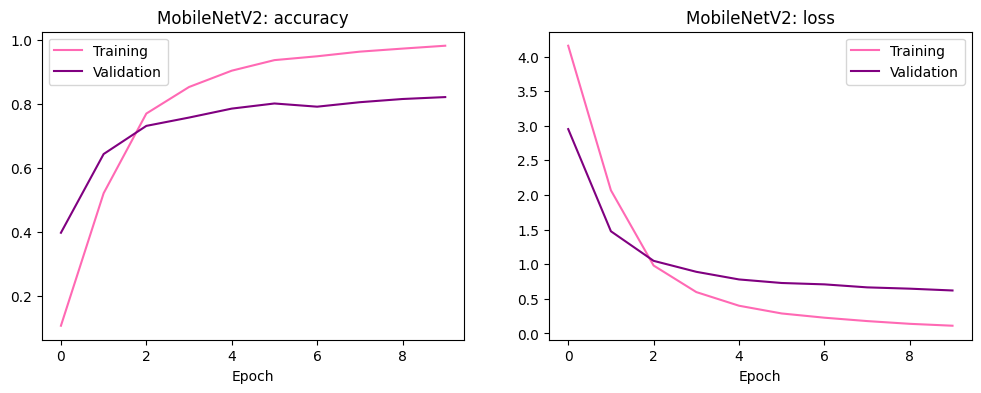

In [33]:
history_mob = mobnet.fit(train_data, validation_data=valid_data, epochs=10)
plot_history(history_mob, 'MobileNetV2')

MobileNetV2: training reaches about 98%, but validation stops at about 82%. The bigger gap means it is memorizing the training photos more than EfficientNetB0 does. The loss graph shows the same thing: the training loss keeps dropping while the validation loss levels off.

## Compare validation accuracy for all three models

In [34]:
# score each model on the validation photos
scores = {}
for name, m in [('Baseline CNN', model), ('EfficientNetB0', effnet), ('MobileNetV2', mobnet)]:
    _, acc = m.evaluate(valid_data, verbose=0)
    scores[name] = round(acc, 3)

print(pd.Series(scores, name='validation accuracy'))

Baseline CNN      0.122
EfficientNetB0    0.858
MobileNetV2       0.822
Name: validation accuracy, dtype: float64


In [36]:
# FINAL TEST: run this cell only once
results = {}
for name, m in [('Baseline CNN', model), ('EfficientNetB0', effnet), ('MobileNetV2', mobnet)]:
    _, acc = m.evaluate(test_data, verbose=0)
    results[name] = round(acc, 3)

print(pd.Series(results, name='test accuracy'))

Baseline CNN      0.124
EfficientNetB0    0.868
MobileNetV2       0.836
Name: test accuracy, dtype: float64


Transfer learning improved accuracy from about 12% (baseline CNN trained from scratch) to about 87% (EfficientNetB0) on the held-out test photos, using only 20 training photos per species. EfficientNetB0 performed slightly better than MobileNetV2 (84%) on both validation and test data.

# more visuals

## Compare all three models (validation vs test)

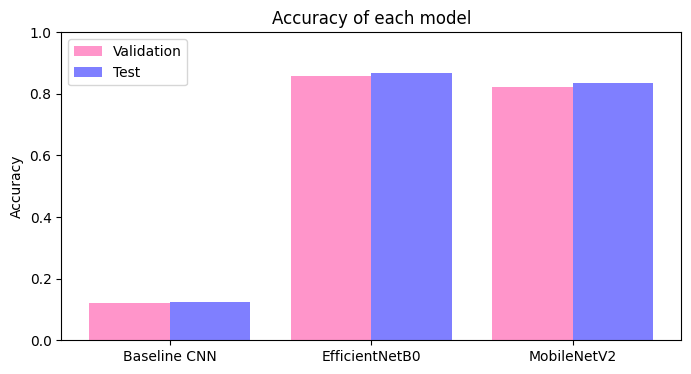

In [47]:
# Bar chart: validation and test accuracy for each model
names = list(scores.keys())
x = np.arange(len(names))

plt.figure(figsize=(8, 4))
plt.bar(x - 0.2, [scores[n] for n in names], width=0.4, label='Validation', color='hotpink',  alpha=0.7)
plt.bar(x + 0.2, [results[n] for n in names], width=0.4, label='Test', color='blue',  alpha=0.5)
plt.xticks(x, names)
plt.ylim(0, 1)
plt.ylabel('Accuracy')
plt.title('Accuracy of each model')
plt.legend()
plt.show()

This chart compares the three models on the validation photos and the test photos. The baseline CNN, which learned from scratch, scored about 12%. Both transfer learning models scored much higher: EfficientNetB0 scored about 86% on validation and 87% on test, and MobileNetV2 scored about 82% and 84%. The test scores are slightly higher than the validation scores for every model, so the results are consistent.

## EfficientNetB0 confusion matrix (validation)

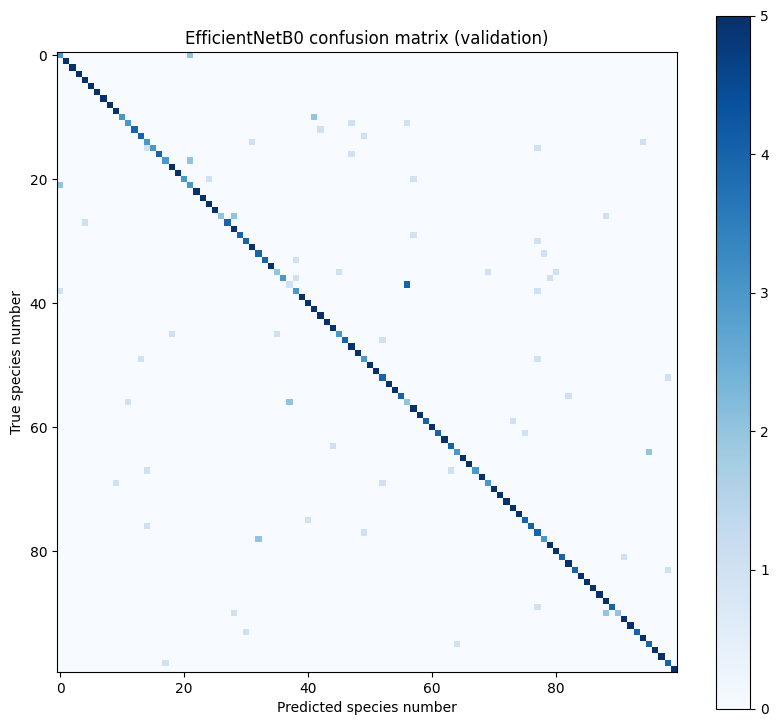

In [49]:
# Mistakes made by the chosen model on the validation photos
probs_eff = effnet.predict(valid_data, verbose=0)
pred_eff = np.argmax(probs_eff, axis=1)
cm_eff = confusion_matrix(y_valid_true, pred_eff, labels=range(100))

plt.figure(figsize=(10, 9))
plt.imshow(cm_eff, cmap='Blues')
plt.title('EfficientNetB0 confusion matrix (validation)')
plt.xlabel('Predicted species number')
plt.ylabel('True species number')
plt.colorbar()
plt.show()

each row is a real species, and each column is what the model guessed. The dark line running from the top left to the bottom right shows the correct guesses, and it is clearly strong across almost all 100 species. The light dots off the line are the mistakes. There are only a few of them, and each is usually one or two photos, so the model rarely confuses one species with another.

## Per-species accuracy, baseline vs EfficientNetB0

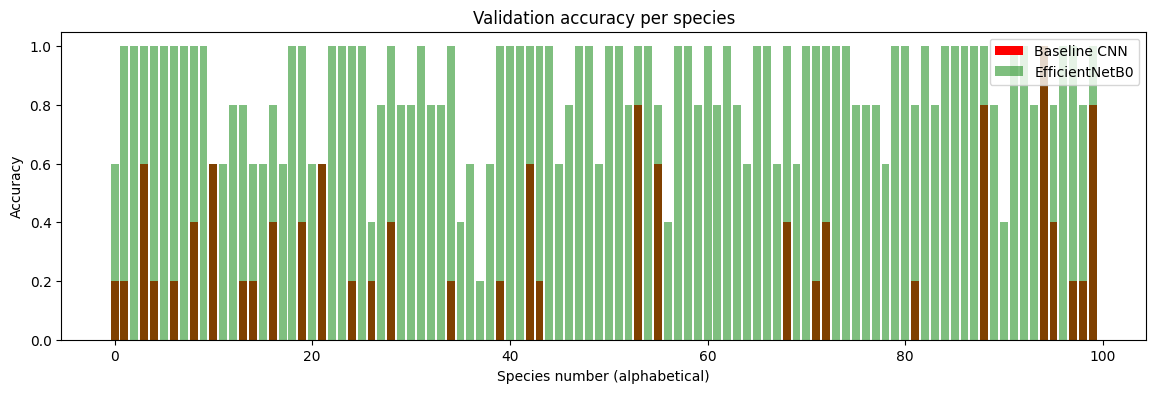

Species EfficientNetB0 never got right: 0


In [52]:
# For each species: how often each model got it right
per_eff = cm_eff.diagonal() / cm_eff.sum(axis=1)

plt.figure(figsize=(14, 4))
plt.bar(range(100), per_class, color='red', label='Baseline CNN')
plt.bar(range(100), per_eff, color='green', alpha=0.5, label='EfficientNetB0')
plt.title('Validation accuracy per species')
plt.xlabel('Species number (alphabetical)')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

print('Species EfficientNetB0 never got right:', (per_eff == 0).sum())

Each bar is one species, and its height is how often the model named it correctly. The green bars are EfficientNetB0, and the red bars are the baseline. Most green bars reach 0.8 or 1.0, which means the model gets most species right almost every time. The baseline bars are short, and many species were never named correctly by the baseline. The bars that are still low for EfficientNetB0 are the species that look most like others.

## Discussion

- **Transfer learning made the biggest difference.** Using the same 20 photos per species, the baseline CNN reached about 12% on the test photos, while EfficientNetB0 reached about 87%.
- **EfficientNetB0 was the best model** on both validation (86%) and test (87%) photos. MobileNetV2 was close (84% on test), but it fit the training photos more closely (about 98% training accuracy vs. about 82% validation).
- **Some species are hard to tell apart.** The confusion matrix shows that the most common mistakes are between species with similar colors and patterns, such as Monarch and Viceroy. Many of these look alike to us people too.
- **Limitations:**
  - Only 20 photos per species were used.
  - Each model was trained for 10 epochs and only once, so the scores could change slightly with another random seed.
  - The pretrained layers were frozen, so they were not adjusted to butterflies.
  - Images were resized to 128 by 128 pixels, which may lose fine detail.
- **Next steps to improve the results:** use more photos per species, train for more epochs, unfreeze the top layers of the pretrained model, and add data augmentation.

## Conclusion

Using transfer learning with EfficientNetB0, we built a model that correctly identifies the species of about 87% of unseen butterfly and moth photos, using only 20 training photos per species. Both transfer learning models performed far better than a small CNN trained from scratch, which reached only about 12%. This shows that pretrained models are a practical choice when labeled data is limited.

## References

- Tan, M., and Le, Q. V. (2019). EfficientNet: Rethinking model scaling for convolutional neural networks. *Proceedings of the 36th International Conference on Machine Learning (ICML)*. https://proceedings.mlr.press/v97/tan19a.html
- Sandler, M., Howard, A., Zhu, M., Zhmoginov, A., and Chen, L.-C. (2018). MobileNetV2: Inverted residuals and linear bottlenecks. *IEEE/CVF Conference on Computer Vision and Pattern Recognition (CVPR)*. https://openaccess.thecvf.com/content_cvpr_2018/html/Sandler_MobileNetV2_Inverted_Residuals_CVPR_2018_paper.html
- gpiosenka. Butterfly & Moths Image Classification 100 Species (version 13). Kaggle, CC0 license. https://www.kaggle.com/datasets/gpiosenka/butterfly-images40-species
- Keras Applications documentation. https://keras.io/api/applications/